# How many trees does the multi-output model actually need?

Open question from `multioutput_tree.ipynb` (baseline 2, `report/log/006_...tex`): Songa_G1 and
Lio_G1 regressed relative to the 14-independent-models baseline, and the working hypothesis was
that 200 trees shared across 14 outputs gives each unit roughly 14x less dedicated capacity than
baseline 1's 200-trees-*each*. This notebook tests that directly: train with a generous cap and
look at validation performance as a function of tree count, both overall and per-unit, rather
than guessing a single number.

**Method note (found while building this):** XGBoost's own `eval_metric="auc"` for a
multi-output/multi-label model is **not** the same number as our official micro-average metric
--- it's noticeably lower and less smooth (verified below), almost certainly because it macro-
averages per-output AUC rather than pooling all unit-hour predictions the way
`kaggle_metric.py` does. So instead of trusting built-in early stopping on that metric, we train
once to a generous tree count with no early stopping, then use `predict_proba(...,
iteration_range=(0, k))` to reconstruct the *official* metric at each checkpoint from that one
trained model --- cheap, since it's just inference, not retraining.


In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from xgboost import XGBClassifier
from sklearn.metrics import roc_auc_score

sys.path.insert(0, "../..")
from kaggle_metric import score as kaggle_score

INK = "#0b0b0b"
INK_SECONDARY = "#52514e"
INK_MUTED = "#898781"
GRID = "#e1e0d9"
BASELINE_COLOR = "#c3c2b7"
SURFACE = "#fcfcfb"
CAT = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "axes.edgecolor": BASELINE_COLOR,
    "axes.labelcolor": INK_SECONDARY, "axes.titlecolor": INK, "text.color": INK,
    "xtick.color": INK_MUTED, "ytick.color": INK_MUTED, "grid.color": GRID,
    "axes.grid": True, "grid.linewidth": 0.8, "axes.spines.top": False,
    "axes.spines.right": False, "font.size": 11, "figure.dpi": 110,
})


## 1. Load, split (identical protocol to baselines 1 and 2)

In [2]:
train_df = pd.read_parquet("../../data/processed/train_hourly.parquet")
train_df["year"] = train_df["starttime"].dt.year

target_cols = [c for c in train_df.columns if c.startswith("on_")]
units = [c[len("on_"):] for c in target_cols]
feature_cols = [c for c in train_df.columns
                if c not in ("run_no", "split", "starttime", "timestamp", "year") and c not in target_cols]

is_val = train_df["year"] == 2022
fit_df, val_df = train_df[~is_val], train_df[is_val]
X_fit, X_val = fit_df[feature_cols], val_df[feature_cols]
Y_fit, Y_val = fit_df[target_cols].astype(int), val_df[target_cols].astype(int)

uc = pd.read_csv("../../data/kernel/Unit_commitment_decisions.csv")
solution_val = uc[uc["Run No"].isin(val_df["run_no"].unique())]

MAX_TREES = 3000
CHECKPOINTS = list(range(25, 500, 25)) + list(range(500, MAX_TREES + 1, 100))
print(f"fit rows: {len(fit_df):,}   val rows: {len(val_df):,}   checkpoints: {CHECKPOINTS}")


fit rows: 429,576   val rows: 61,320   checkpoints: [25, 50, 75, 100, 125, 150, 175, 200, 225, 250, 275, 300, 325, 350, 375, 400, 425, 450, 475, 500, 600, 700, 800, 900, 1000, 1100, 1200, 1300, 1400, 1500, 1600, 1700, 1800, 1900, 2000, 2100, 2200, 2300, 2400, 2500, 2600, 2700, 2800, 2900, 3000]


## 2. Train once to 500 trees, no early stopping

Everything else identical to baseline 2 (same 54 features, same `max_depth`/`learning_rate`/
`subsample`/`colsample_bytree`, same `multi_strategy="multi_output_tree"`) --- only
`n_estimators` is raised, specifically to see where the validation curve stops improving.


In [3]:
model = XGBClassifier(
    n_estimators=MAX_TREES, max_depth=6, learning_rate=0.1,
    subsample=0.8, colsample_bytree=0.8,
    tree_method="hist", multi_strategy="multi_output_tree",
    objective="binary:logistic", eval_metric="auc", n_jobs=-1, random_state=0,
)
model.fit(X_fit, Y_fit, eval_set=[(X_val, Y_val)], verbose=False)
print("trained", MAX_TREES, "trees")


trained 3000 trees


## 3. XGBoost's own multi-output `auc` vs. the official micro-AUC (why we don't trust the former for early stopping)

In [4]:
xgb_internal_auc = model.evals_result()["validation_0"]["auc"]

def official_micro_auc(k):
    proba = model.predict_proba(X_val, iteration_range=(0, k))
    val_pred = pd.DataFrame({"run_no": val_df["run_no"].values, "hour": val_df["hour"].values})
    for i, u in enumerate(units):
        val_pred[f"pred_{u}"] = proba[:, i]
    wide = []
    for u in units:
        piv = val_pred.pivot(index="run_no", columns="hour", values=f"pred_{u}")
        piv.columns = [f"result_committed_{u}_t{h}" for h in piv.columns]
        wide.append(piv)
    sub = pd.concat(wide, axis=1).reset_index().rename(columns={"run_no": "Run No"})
    return kaggle_score(solution_val, sub), val_pred

rows = []
per_unit_curves = {u: [] for u in units}
for k in CHECKPOINTS:
    overall, val_pred = official_micro_auc(k)
    rows.append({"n_trees": k, "xgb_internal_auc": xgb_internal_auc[k - 1], "official_micro_auc": overall})
    for u in units:
        per_unit_curves[u].append(roc_auc_score(val_df[f"on_{u}"], val_pred[f"pred_{u}"]))

curve_df = pd.DataFrame(rows)
curve_df


,n_trees,xgb_internal_auc,official_micro_auc
0,25,0.556703,0.622392
1,50,0.587968,0.642056
2,75,0.610683,0.656533
3,100,0.624675,0.667920
4,125,0.654268,0.684298
5,150,0.652696,0.685726
6,175,0.650133,0.684175
7,200,0.653393,0.686982
8,225,0.653044,0.686406
9,250,0.652205,0.686726


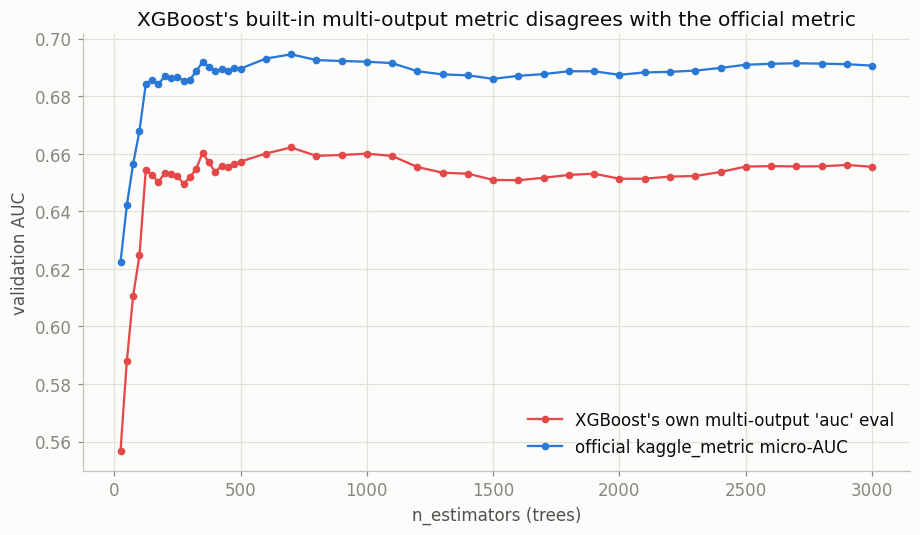

In [5]:
fig, ax = plt.subplots(figsize=(8.5, 5))
ax.plot(curve_df["n_trees"], curve_df["xgb_internal_auc"], color=CAT[7], marker="o", ms=4,
        label="XGBoost's own multi-output 'auc' eval")
ax.plot(curve_df["n_trees"], curve_df["official_micro_auc"], color=CAT[0], marker="o", ms=4,
        label="official kaggle_metric micro-AUC")
ax.set_xlabel("n_estimators (trees)")
ax.set_ylabel("validation AUC")
ax.set_title("XGBoost's built-in multi-output metric disagrees with the official metric")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()


**Finding.** XGBoost's own multi-output `auc` tracks noticeably below and noisier than the
official micro-AUC --- confirming it's computing something different (almost certainly a
macro-average across the 14 outputs, unweighted by how many predictions each contributes,
versus `kaggle_metric.py`'s pooled/micro calculation). Using the built-in metric for early
stopping in this multi-output setup would optimize the wrong target. Everything below uses the
official metric only.


## 4. Where does the official metric actually plateau?

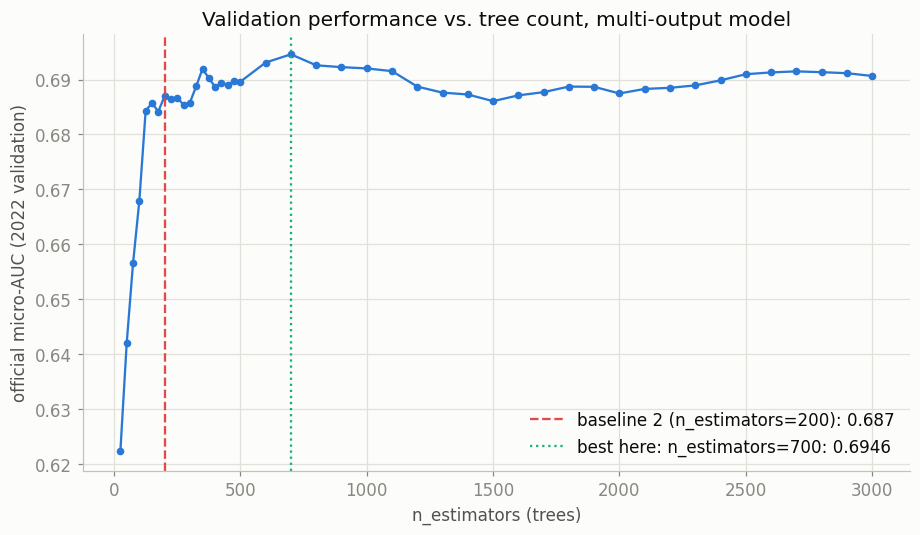

Best checkpoint: n_estimators=700, official micro-AUC=0.6946
Baseline 2 (n_estimators=200) was: 0.6870


In [6]:
best_row = curve_df.loc[curve_df["official_micro_auc"].idxmax()]

fig, ax = plt.subplots(figsize=(8.5, 5))
ax.plot(curve_df["n_trees"], curve_df["official_micro_auc"], color=CAT[0], marker="o", ms=4)
ax.axvline(200, color=CAT[7], lw=1.5, ls="--", label="baseline 2 (n_estimators=200): 0.687")
ax.axvline(best_row["n_trees"], color=CAT[2], lw=1.5, ls=":",
           label=f"best here: n_estimators={int(best_row['n_trees'])}: {best_row['official_micro_auc']:.4f}")
ax.set_xlabel("n_estimators (trees)")
ax.set_ylabel("official micro-AUC (2022 validation)")
ax.set_title("Validation performance vs. tree count, multi-output model")
ax.legend(frameon=False, loc="lower right")
plt.tight_layout()
plt.show()

print(f"Best checkpoint: n_estimators={int(best_row['n_trees'])}, official micro-AUC={best_row['official_micro_auc']:.4f}")
print(f"Baseline 2 (n_estimators=200) was: 0.6870")


## 5. Does more capacity actually help the units that regressed?

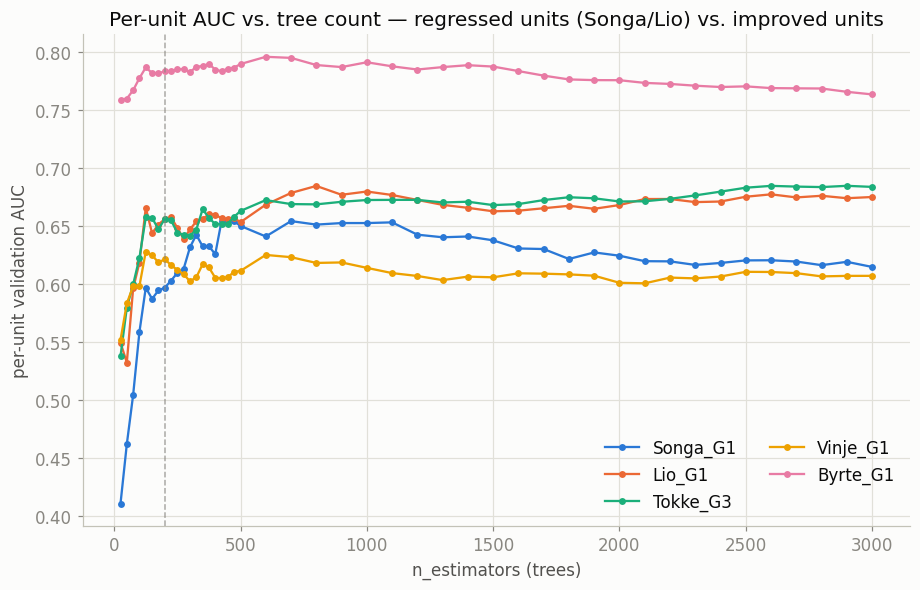

Vinje_G3          0.600065
Tokke_G2          0.609011
Haukeli_G1        0.610215
Kjela_G1          0.612251
Vinje_G2          0.615995
Vinje_G1          0.623495
Tokke_G4          0.633098
Songa_G1          0.654592
Tokke_G3          0.669267
Lio_G1            0.678876
Tokke_G1          0.691461
Hogga_G1          0.703377
Vesle_Kjela_G1    0.773887
Byrte_G1          0.795338
dtype: float64

In [7]:
highlight_units = ["Songa_G1", "Lio_G1", "Tokke_G3", "Vinje_G1", "Byrte_G1"]

fig, ax = plt.subplots(figsize=(8.5, 5.5))
for i, u in enumerate(highlight_units):
    ax.plot(curve_df["n_trees"], per_unit_curves[u], color=CAT[i], marker="o", ms=3.5, label=u)
ax.axvline(200, color=INK_MUTED, lw=1, ls="--", alpha=0.7)
ax.set_xlabel("n_estimators (trees)")
ax.set_ylabel("per-unit validation AUC")
ax.set_title("Per-unit AUC vs. tree count — regressed units (Songa/Lio) vs. improved units")
ax.legend(frameon=False, ncol=2)
plt.tight_layout()
plt.show()

per_unit_at_best = pd.Series({u: per_unit_curves[u][CHECKPOINTS.index(int(best_row['n_trees']))] for u in units}).sort_values()
per_unit_at_best
